In [4]:
#Importando bibliotecas

import os
import pandas as pd
import matplotlib.pyplot as plt

In [5]:
# Criando o DataFrame a partir do arquivo
arquivo = "data/RESULTADO_2025_30000.csv"

if not os.path.exists(arquivo):
    raise FileNotFoundError("Arquivo não encontrado. Abra o notebook na pasta principal do projeto.")

df = pd.read_csv(arquivo, sep=";", encoding="utf-16", decimal=",")
df.columns = df.columns.str.strip()

In [6]:
# Criando uma pasta para armazenar os gráficos
os.makedirs("graficos", exist_ok=True)

In [7]:
#Informações sobre o DF original

print("Linhas e colunas:", df.shape)
print("Quantidade de participantes:", len(df))
print("Total de colunas:", len(df.columns))
print("Registros repetidos no identificador:", df["NU_SEQUENCIAL"].duplicated().sum())
display(df.head(3))

Linhas e colunas: (29999, 70)
Quantidade de participantes: 29999
Total de colunas: 70
Registros repetidos no identificador: 0


,NU_SEQUENCIAL,NU_ANO,CO_ESCOLA,CO_MUNICIPIO_ESC,NO_MUNICIPIO_ESC,CO_UF_ESC,SG_UF_ESC,TP_DEPENDENCIA_ADM_ESC,TP_LOCALIZACAO_ESC,TP_SIT_FUNC_ESC,...,NU_NOTA_COMP3_AV3,NU_NOTA_COMP4_AV3,NU_NOTA_COMP5_AV3,TP_STATUS_REDACAO_AV4,NU_NOTA_AV4,NU_NOTA_COMP1_AV4,NU_NOTA_COMP2_AV4,NU_NOTA_COMP3_AV4,NU_NOTA_COMP4_AV4,NU_NOTA_COMP5_AV4
0,206403,2025,33083592,3304557,Rio de Janeiro,33,RJ,2,1,1,...,,,,,,,,,,
1,3604651,2025,21017115,2111300,São Luís,21,MA,2,1,1,...,,,,,,,,,,
2,1461268,2025,,,,,,,,,...,,,,,,,,,,


Notas preenchidas em cada prova:
NU_NOTA_CN         20365
NU_NOTA_CH         21633
NU_NOTA_LC         21633
NU_NOTA_MT         20365
NU_NOTA_REDACAO    21633
dtype: int64

Tipos de escola que aparecem no arquivo:
TP_DEPENDENCIA_ADM_ESC
1.0      459
2.0     8460
3.0       61
4.0     1714
NaN    19305
Name: count, dtype: int64

Localizações de escola que aparecem no arquivo:
TP_LOCALIZACAO_ESC
1.0    10157
2.0      537
NaN    19305
Name: count, dtype: int64
Registros com tipo de escola informado: 10694

Médias por tipo de escola:
                NU_NOTA_CN  NU_NOTA_CH  NU_NOTA_LC  NU_NOTA_MT  \
Tipo de escola                                                   
Federal              529.3       543.4       561.5       578.3   
Estadual             472.2       483.6       507.8       482.6   
Municipal            504.5       531.0       555.3       533.8   
Privada              552.1       566.7       578.9       617.3   

                NU_NOTA_REDACAO  
Tipo de escola                   
F

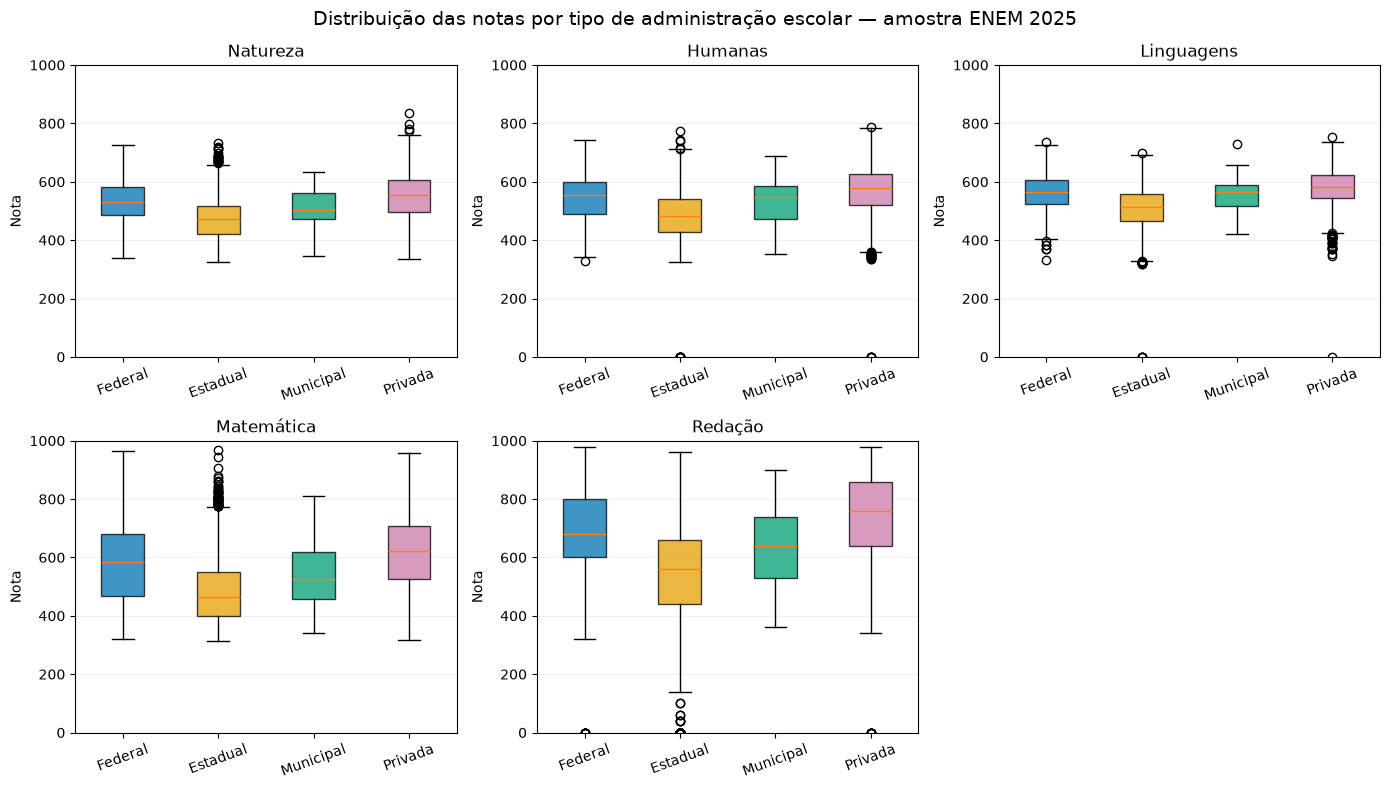

In [ ]:
# Colunas de nota que vamos analisar
notas = ["NU_NOTA_CN", "NU_NOTA_CH", "NU_NOTA_LC", "NU_NOTA_MT", "NU_NOTA_REDACAO"]
competencias = ["NU_NOTA_COMP1", "NU_NOTA_COMP2", "NU_NOTA_COMP3", "NU_NOTA_COMP4", "NU_NOTA_COMP5"]

# Transformando as notas em números
colunas_numericas = notas + competencias + ["NU_NOTA_AV1", "NU_NOTA_AV2", "NU_NOTA_AV3", "NU_NOTA_AV4"]

for coluna in colunas_numericas:
    df[coluna] = pd.to_numeric(
        df[coluna].astype(str).str.replace(",", ".", regex=False),
        errors="coerce"
    )

# Transformando os códigos dos grupos em números
categorias = ["TP_DEPENDENCIA_ADM_ESC", "TP_LOCALIZACAO_ESC", "TP_LINGUA",
              "TP_PRESENCA_CH", "TP_PRESENCA_MT"]

# Se o arquivo não tiver presença de CN ou LC, usamos a prova do mesmo dia
for coluna, referencia in [("TP_PRESENCA_CN", "TP_PRESENCA_MT"),
                           ("TP_PRESENCA_LC", "TP_PRESENCA_CH")]:
    if coluna not in df.columns:
        df[coluna] = df[referencia]
        print("Aviso:", coluna, "não existe. Usando a presença de", referencia)
    categorias.append(coluna)

for coluna in categorias:
    df[coluna] = pd.to_numeric(df[coluna], errors="coerce")

print("Notas preenchidas em cada prova:")
print(df[notas].count())

print("\nTipos de escola que aparecem no arquivo:")
print(df["TP_DEPENDENCIA_ADM_ESC"].value_counts(dropna=False).sort_index())

print("\nLocalizações de escola que aparecem no arquivo:")
print(df["TP_LOCALIZACAO_ESC"].value_counts(dropna=False).sort_index())

# Desempenho por tipo de escola
tipos_escola = {1: "Federal", 2: "Estadual", 3: "Municipal", 4: "Privada"}
cores_escola = {
    "Federal": "#0072B2",
    "Estadual": "#E69F00",
    "Municipal": "#009E73",
    "Privada": "#CC79A7",
}
nomes_notas = ["Natureza", "Humanas", "Linguagens", "Matemática", "Redação"]

escolas = df.copy()
escolas["Tipo de escola"] = escolas["TP_DEPENDENCIA_ADM_ESC"].map(tipos_escola)

print("Registros com tipo de escola informado:", escolas["Tipo de escola"].notna().sum())
media_escolas = escolas.groupby("Tipo de escola")[notas].mean().reindex(tipos_escola.values())
qtd_escolas = escolas.groupby("Tipo de escola")[notas].count().reindex(tipos_escola.values())

print("\nMédias por tipo de escola:")
print(media_escolas.round(1).dropna(how="all"))
print("\nQuantidade de notas usadas por tipo de escola:")
print(qtd_escolas.dropna(how="all"))

if media_escolas.notna().any().any():
    fig, eixos = plt.subplots(2, 3, figsize=(14, 8))

    for i, nota in enumerate(notas):
        ax = eixos.flat[i]
        distribuicoes = []
        tipos_presentes = []

        for localizacao in tipos_escola.values():
            valores = escolas.loc[escolas["Tipo de escola"] == localizacao, nota].dropna()
            if not valores.empty:
                distribuicoes.append(valores)
                tipos_presentes.append(localizacao)

        if distribuicoes:
            caixas = ax.boxplot(
                distribuicoes,
                tick_labels=tipos_presentes,
                showfliers=True,
                patch_artist=True
            )
            for caixa, localizacao in zip(caixas["boxes"], tipos_presentes):
                caixa.set_facecolor(cores_escola[localizacao])
                caixa.set_alpha(0.75)
        else:
            ax.text(0.5, 0.5, "Sem notas disponíveis", ha="center", va="center", transform=ax.transAxes)

        ax.set_title(nomes_notas[i])
        ax.set_ylabel("Nota")
        ax.set_ylim(0, 1000)
        ax.tick_params(axis="x", rotation=20)
        ax.grid(axis="y", alpha=0.2)

    eixos.flat[5].axis("off")
    fig.suptitle("Distribuição das notas por tipo de administração escolar — amostra ENEM 2025", fontsize=14)
    plt.tight_layout()
    plt.savefig("graficos/01_notas_por_tipo_escola.png", dpi=160, bbox_inches="tight")
    plt.show()
else:
    print("\nNão foi possível comparar os tipos de escola.")
    print("O arquivo não tem registros com tipo de escola e nota preenchidos ao mesmo tempo.")
    print("Não vamos inventar uma comparação que a amostra não permite.")

Notas preenchidas em cada prova:
NU_NOTA_CN         20365
NU_NOTA_CH         21633
NU_NOTA_LC         21633
NU_NOTA_MT         20365
NU_NOTA_REDACAO    21633
dtype: int64

Tipos de escola que aparecem no arquivo:
TP_DEPENDENCIA_ADM_ESC
1.0      459
2.0     8460
3.0       61
4.0     1714
NaN    19305
Name: count, dtype: int64

Localizações de escola que aparecem no arquivo:
TP_LOCALIZACAO_ESC
1.0    10157
2.0      537
NaN    19305
Name: count, dtype: int64
Registros com localização de escola informado: 10694

Médias por localizacao de escola:
                       NU_NOTA_CN  NU_NOTA_CH  NU_NOTA_LC  NU_NOTA_MT  \
Localizacao de escola                                                   
Urbana                      492.5       504.6       526.4       517.2   
Rural                       469.5       471.9       489.3       468.6   

                       NU_NOTA_REDACAO  
Localizacao de escola                   
Urbana                           578.8  
Rural                            504

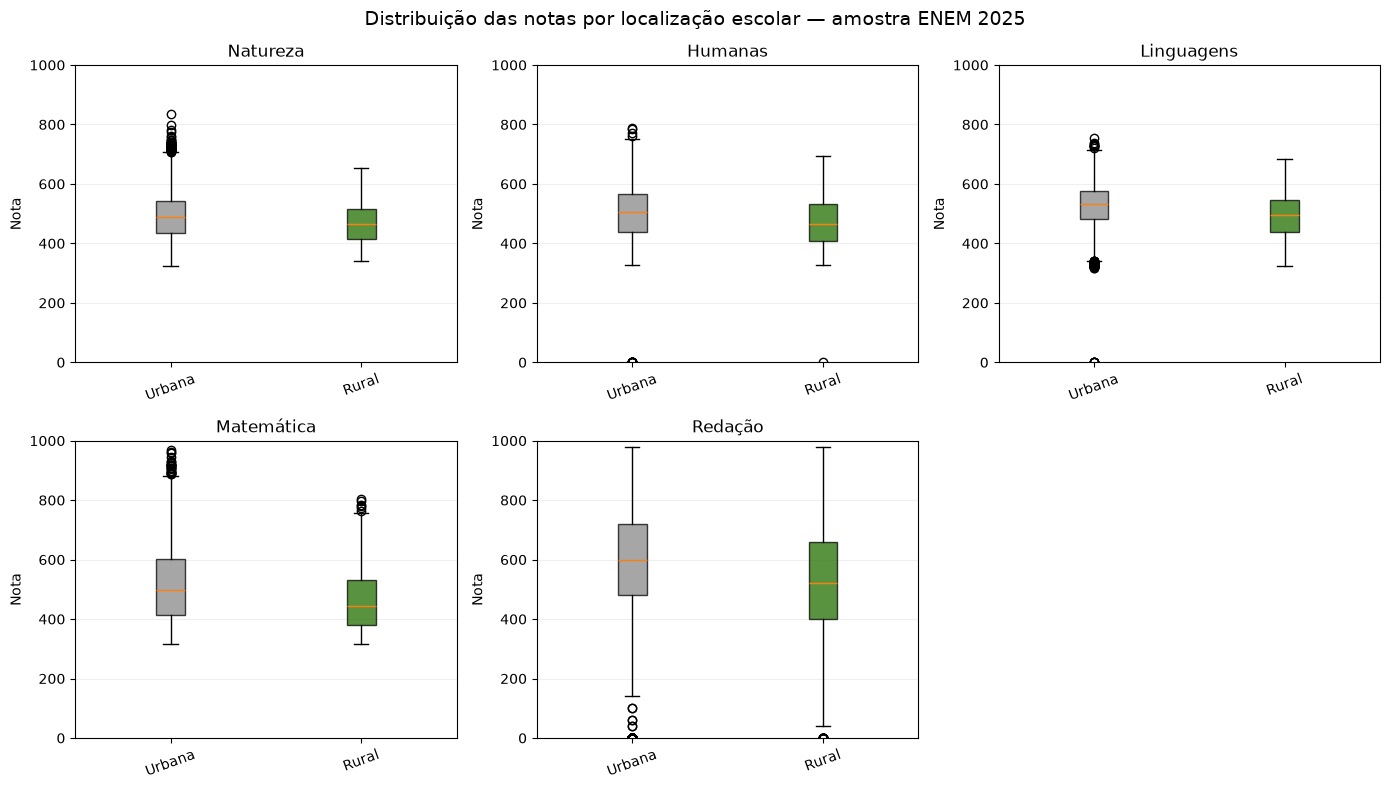

In [ ]:
# Colunas de nota que vamos analisar
notas = ["NU_NOTA_CN", "NU_NOTA_CH", "NU_NOTA_LC", "NU_NOTA_MT", "NU_NOTA_REDACAO"]
competencias = ["NU_NOTA_COMP1", "NU_NOTA_COMP2", "NU_NOTA_COMP3", "NU_NOTA_COMP4", "NU_NOTA_COMP5"]

# Transformando as notas em números
colunas_numericas = notas + competencias + ["NU_NOTA_AV1", "NU_NOTA_AV2", "NU_NOTA_AV3", "NU_NOTA_AV4"]

for coluna in colunas_numericas:
    df[coluna] = pd.to_numeric(
        df[coluna].astype(str).str.replace(",", ".", regex=False),
        errors="coerce"
    )

# Transformando os códigos dos grupos em números
categorias = ["TP_DEPENDENCIA_ADM_ESC", "TP_LOCALIZACAO_ESC", "TP_LINGUA",
              "TP_PRESENCA_CH", "TP_PRESENCA_MT"]

# Se o arquivo não tiver presença de CN ou LC, usamos a prova do mesmo dia
for coluna, referencia in [("TP_PRESENCA_CN", "TP_PRESENCA_MT"),
                           ("TP_PRESENCA_LC", "TP_PRESENCA_CH")]:
    if coluna not in df.columns:
        df[coluna] = df[referencia]
        print("Aviso:", coluna, "não existe. Usando a presença de", referencia)
    categorias.append(coluna)

for coluna in categorias:
    df[coluna] = pd.to_numeric(df[coluna], errors="coerce")

print("Notas preenchidas em cada prova:")
print(df[notas].count())

print("\nTipos de escola que aparecem no arquivo:")
print(df["TP_DEPENDENCIA_ADM_ESC"].value_counts(dropna=False).sort_index())

print("\nLocalizações de escola que aparecem no arquivo:")
print(df["TP_LOCALIZACAO_ESC"].value_counts(dropna=False).sort_index())

# Desempenho por localização de escola
localizacao_escola = {1: "Urbana", 2: "Rural"}
cores_escola = {
    "Urbana": "#888888",
    "Rural": "#236F00FF",
}
nomes_notas = ["Natureza", "Humanas", "Linguagens", "Matemática", "Redação"]

escolas = df.copy()
escolas["Localizacao de escola"] = escolas["TP_LOCALIZACAO_ESC"].map(localizacao_escola)

print("Registros com localização de escola informado:", escolas["Localizacao de escola"].notna().sum())
media_escolas = escolas.groupby("Localizacao de escola")[notas].mean().reindex(localizacao_escola.values())
qtd_escolas = escolas.groupby("Localizacao de escola")[notas].count().reindex(localizacao_escola.values())

print("\nMédias por localizacao de escola:")
print(media_escolas.round(1).dropna(how="all"))
print("\nQuantidade de notas usadas por localizacao de escola:")
print(qtd_escolas.dropna(how="all"))

if media_escolas.notna().any().any():
    fig, eixos = plt.subplots(2, 3, figsize=(14, 8))

    for i, nota in enumerate(notas):
        ax = eixos.flat[i]
        distribuicoes = []
        tipos_presentes = []

        for localizacao in localizacao_escola.values():
            valores = escolas.loc[escolas["Localizacao de escola"] == localizacao, nota].dropna()
            if not valores.empty:
                distribuicoes.append(valores)
                tipos_presentes.append(localizacao)

        if distribuicoes:
            caixas = ax.boxplot(
                distribuicoes,
                tick_labels=tipos_presentes,
                showfliers=True,
                patch_artist=True
            )
            for caixa, localizacao in zip(caixas["boxes"], tipos_presentes):
                caixa.set_facecolor(cores_escola[localizacao])
                caixa.set_alpha(0.75)
        else:
            ax.text(0.5, 0.5, "Sem notas disponíveis", ha="center", va="center", transform=ax.transAxes)

        ax.set_title(nomes_notas[i])
        ax.set_ylabel("Nota")
        ax.set_ylim(0, 1000)
        ax.tick_params(axis="x", rotation=20)
        ax.grid(axis="y", alpha=0.2)

    eixos.flat[5].axis("off")
    fig.suptitle("Distribuição das notas por localização escolar — amostra ENEM 2025", fontsize=14)
    plt.tight_layout()
    plt.savefig("graficos/02_notas_por_tipo_escola.png", dpi=160, bbox_inches="tight")
    plt.show()
else:
    print("\nNão foi possível comparar os tipos de escola.")
    print("O arquivo não tem registros com localizacao de escola e nota preenchidos ao mesmo tempo.")
    print("Não vamos inventar uma comparação que a amostra não permite.")

Natureza
Participantes com nota positiva: 20364
Registros com nota zero: 1
Menor nota positiva: 324.3
Maior nota: 858.7

Humanas
Participantes com nota positiva: 21577
Registros com nota zero: 56
Menor nota positiva: 325.9
Maior nota: 793.7

Linguagens
Participantes com nota positiva: 21621
Registros com nota zero: 12
Menor nota positiva: 316.2
Maior nota: 794.5

Matemática
Participantes com nota positiva: 20364
Registros com nota zero: 1
Menor nota positiva: 315.0
Maior nota: 967.7



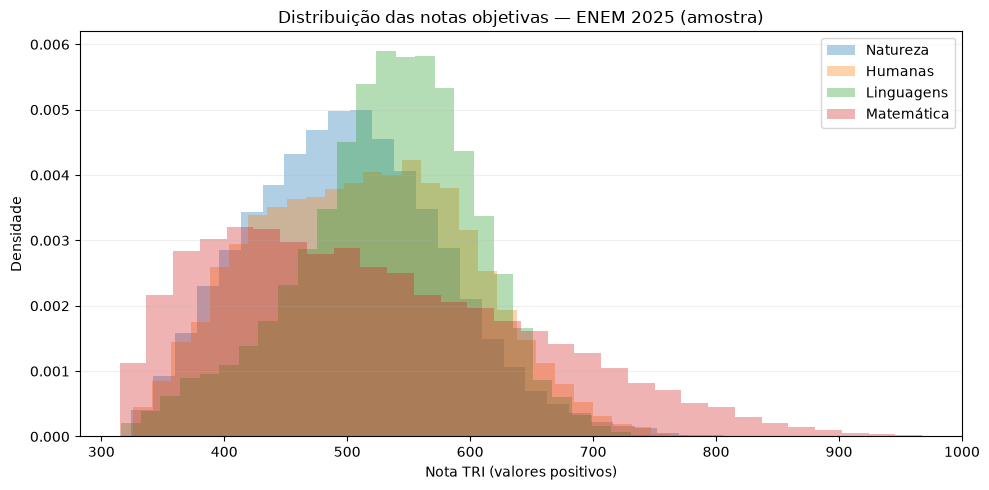

In [26]:
#Distribuição das notas objetivas

areas = {
    "NU_NOTA_CN": ("Natureza", "TP_PRESENCA_CN"),
    "NU_NOTA_CH": ("Humanas", "TP_PRESENCA_CH"),
    "NU_NOTA_LC": ("Linguagens", "TP_PRESENCA_LC"),
    "NU_NOTA_MT": ("Matemática", "TP_PRESENCA_MT")
}

plt.figure(figsize=(10, 5))
quantidade_areas = 0

for coluna, (nome, presenca) in areas.items():
    # Considera somente os participantes presentes na prova
    valores = df.loc[df[presenca] == 1, coluna].dropna()

    # As notas zero são contadas, mas não entram no histograma
    zeros = (valores == 0).sum()
    notas_positivas = valores[valores > 0]

    print(nome)
    print("Participantes com nota positiva:", len(notas_positivas))
    print("Registros com nota zero:", zeros)
    if len(notas_positivas) > 0:
        print("Menor nota positiva:", round(notas_positivas.min(), 1))
        print("Maior nota:", round(notas_positivas.max(), 1))
        plt.hist(notas_positivas, bins=30, density=True, alpha=0.35, label=nome)
        quantidade_areas += 1
    print()

if quantidade_areas > 0:
    plt.title("Distribuição das notas objetivas — ENEM 2025 (amostra)")
    plt.xlabel("Nota TRI (valores positivos)")
    plt.ylabel("Densidade")
    plt.legend()
    plt.grid(axis="y", alpha=0.2)
    plt.tight_layout()
    plt.savefig("graficos/09_distribuicao_notas.png", dpi=160, bbox_inches="tight")
    plt.show()
else:
    plt.close()
    print("Não foram encontradas notas positivas para montar o histograma.")

Participantes com as cinco notas: 20262
Quantidade de UFs encontradas: 27

Dez maiores médias por UF (amostra):
             Média geral  Participantes
SG_UF_PROVA                            
SP                 560.0           3184
DF                 556.9            356
SC                 555.9            450
MG                 553.1           1868
RS                 552.8            744
ES                 550.4            343
RJ                 550.1           1416
PR                 546.8            893
GO                 536.6            653
RN                 531.9            504

Estados com notas e desenho correspondente: 27
UFs que receberão cor: AC, AL, AM, AP, BA, CE, DF, ES, GO, MA, MG, MS, MT, PA, PB, PE, PI, PR, RJ, RN, RO, RR, RS, SC, SE, SP, TO


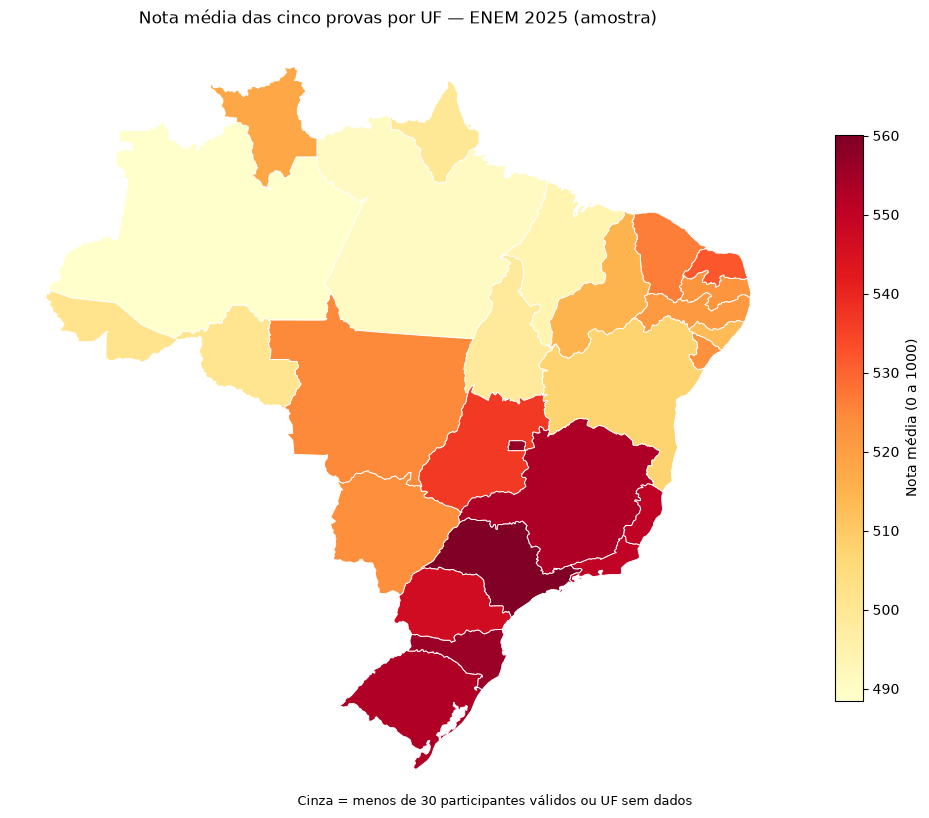

In [27]:
import json
from urllib.request import urlretrieve
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

# Selecionando quem tem todas as notas e participou dos dois dias
completos = df.dropna(subset=notas).copy()
completos = completos[
    (completos["TP_PRESENCA_CN"] == 1) &
    (completos["TP_PRESENCA_CH"] == 1) &
    (completos["TP_PRESENCA_LC"] == 1) &
    (completos["TP_PRESENCA_MT"] == 1)
].copy()

# Padronizando as siglas de UF: por exemplo, " sp " vira "SP"
completos["SG_UF_PROVA"] = (
    completos["SG_UF_PROVA"]
    .astype("string")
    .str.strip()
    .str.upper()
    .str.replace(r"[^A-Z]", "", regex=True)
)

completos["Média geral"] = completos[notas].mean(axis=1)
ranking = completos.groupby("SG_UF_PROVA")["Média geral"].agg(["mean", "count"])
ranking.columns = ["Média geral", "Participantes"]
ranking = ranking.sort_values("Média geral", ascending=False)

print("Participantes com as cinco notas:", len(completos))
print("Quantidade de UFs encontradas:", len(ranking))
print("\nDez maiores médias por UF (amostra):")
print(ranking.head(10).round(1))

# Guardando a tabela completa para consulta
ranking.to_csv("graficos/11_notas_por_uf.csv", sep=";", decimal=",")

# Evita destacar médias com poucas observações
ranking_mapa = ranking[ranking["Participantes"] >= 30]

if ranking_mapa.empty:
    print("Não há estados com pelo menos 30 participantes e notas válidas.")
else:
    arquivo_mapa = "data/estados_br.geojson"
    endereco_mapa = "https://raw.githubusercontent.com/henriquemalvar/br-geojson/main/dist/estados.geojson"

    # Baixa a malha só na primeira execução
    if not os.path.exists(arquivo_mapa):
        try:
            urlretrieve(endereco_mapa, arquivo_mapa)
            print("Mapa geográfico baixado com sucesso.")
        except Exception as erro:
            print("Erro ao baixar o mapa:", erro)
            print("Baixe manualmente:", endereco_mapa)

    if os.path.exists(arquivo_mapa):
        with open(arquivo_mapa, "r", encoding="utf-8") as arquivo_geo:
            estados = json.load(arquivo_geo)["features"]

        # Conferindo as siglas do arquivo geográfico
        siglas_mapa = set()
        for estado in estados:
            sigla = str(estado["properties"]["sigla"]).strip().upper()
            siglas_mapa.add(sigla)

        # Só estas UFs serão pintadas com uma cor
        ufs_coloridas = set(ranking_mapa.index) & siglas_mapa
        print("\nEstados com notas e desenho correspondente:", len(ufs_coloridas))
        print("UFs que receberão cor:", ", ".join(sorted(ufs_coloridas)))

        faltando = set(ranking_mapa.index) - siglas_mapa
        if faltando:
            print("UFs do CSV sem correspondência no mapa:", sorted(faltando))

        if len(ufs_coloridas) == 0:
            print("Não foi encontrada nenhuma UF em comum entre o CSV e o mapa.")
            print("Confira os valores de SG_UF_PROVA e as siglas no arquivo GeoJSON.")
        else:
            medias_coloridas = ranking_mapa.loc[list(ufs_coloridas), "Média geral"]
            minimo = medias_coloridas.min()
            maximo = medias_coloridas.max()
            if minimo == maximo:
                maximo = minimo + 1

            paleta = plt.get_cmap("YlOrRd")
            escala = Normalize(vmin=minimo, vmax=maximo)
            fig, ax = plt.subplots(figsize=(10, 9))

            for estado in estados:
                sigla = str(estado["properties"]["sigla"]).strip().upper()
                desenho = estado["geometry"]

                if sigla in ufs_coloridas:
                    nota = ranking_mapa.loc[sigla, "Média geral"]
                    cor = paleta(escala(nota))
                else:
                    cor = "#dedede"

                if desenho["type"] == "Polygon":
                    partes = [desenho["coordinates"]]
                else:
                    partes = desenho["coordinates"]

                for parte in partes:
                    contorno = parte[0]
                    x = [ponto[0] for ponto in contorno]
                    y = [ponto[1] for ponto in contorno]
                    ax.fill(x, y, color=cor, edgecolor="white", linewidth=0.7)

            ax.set_aspect("equal")
            ax.axis("off")
            ax.set_title("Nota média das cinco provas por UF — ENEM 2025 (amostra)")
            barra = ScalarMappable(norm=escala, cmap=paleta)
            barra.set_array([])
            fig.colorbar(barra, ax=ax, label="Nota média (0 a 1000)", shrink=0.65)
            fig.text(0.5, 0.07, "Cinza = menos de 30 participantes válidos ou UF sem dados", ha="center", fontsize=9)
            plt.tight_layout()
            plt.savefig("graficos/11_mapa_notas_por_uf.png", dpi=160, bbox_inches="tight")
            plt.show()

Registros com redação e localização de escola: 8337
             Quantidade  Acima de 800 (%)
Localização                              
Rural               379              6.33
Urbana             7958             13.92


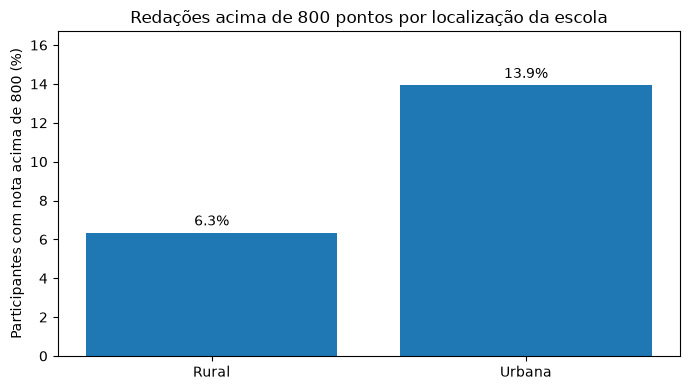

In [ ]:
#Escola urbana ou rural e redações acima de 800

localizacao = {1: "Urbana", 2: "Rural"}

redacoes_local = df[df["NU_NOTA_REDACAO"].notna()].copy()
redacoes_local["Localização"] = redacoes_local["TP_LOCALIZACAO_ESC"].map(localizacao)
redacoes_local = redacoes_local.dropna(subset=["Localização"])
redacoes_local["Acima de 800"] = redacoes_local["NU_NOTA_REDACAO"] > 800

percentual_800 = redacoes_local.groupby("Localização")["Acima de 800"].mean() * 100
quantidade_local = redacoes_local["Localização"].value_counts()

print("Registros com redação e localização de escola:", len(redacoes_local))
print(pd.DataFrame({"Quantidade": quantidade_local,
                    "Acima de 800 (%)": percentual_800}).round(2))

if not percentual_800.empty:
    plt.figure(figsize=(7, 4))
    barras = plt.bar(percentual_800.index, percentual_800.values)
    plt.bar_label(barras, fmt="%.1f%%", padding=3)
    plt.title("Redações acima de 800 pontos por localização da escola")
    plt.ylabel("Participantes com nota acima de 800 (%)")
    plt.ylim(0, max(percentual_800.max() * 1.2, 1))
    plt.tight_layout()
    plt.savefig("graficos/03_urbana_rural.png", dpi=160)
    plt.show()
else:
    print("Não há registros suficientes de escola urbana/rural na amostra.")
    print("Por isso, não será mostrado um gráfico vazio.")

Distribuição das redações por número de avaliações:
              Quantidade  Percentual (%)
2 avaliações       14523           67.13
3 avaliações        5979           27.64
4 avaliações        1131            5.23


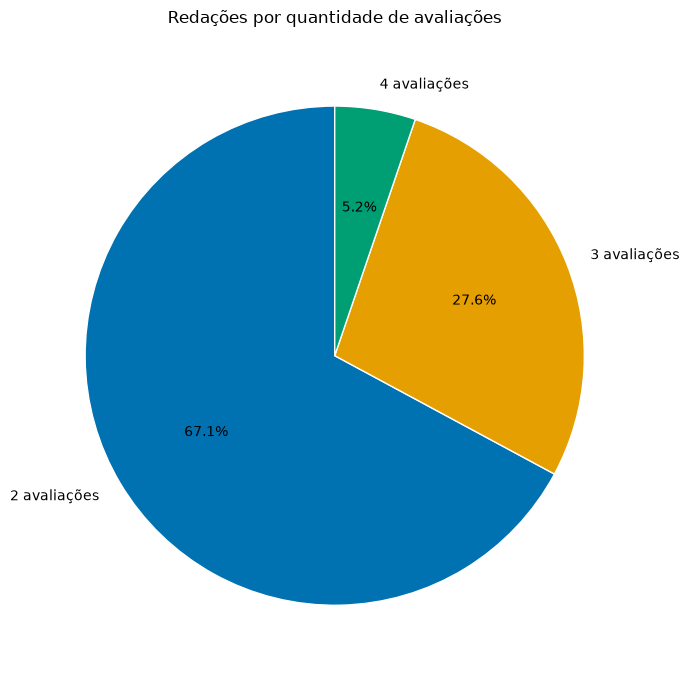

In [20]:
# Quantidade de avaliações recebidas por redação
colunas_avaliacoes = ["NU_NOTA_AV1", "NU_NOTA_AV2", "NU_NOTA_AV3", "NU_NOTA_AV4"]
redacoes_avaliadas = df.loc[df["NU_NOTA_REDACAO"].notna(), colunas_avaliacoes].notna().sum(axis=1)
redacoes_por_avaliacoes = redacoes_avaliadas[redacoes_avaliadas.isin([2, 3, 4])]
quantidade_avaliacoes = redacoes_por_avaliacoes.value_counts().reindex([2, 3, 4], fill_value=0)
rotulos_avaliacoes = ["2 avaliações", "3 avaliações", "4 avaliações"]

if quantidade_avaliacoes.sum() > 0:
    percentuais_avaliacoes = quantidade_avaliacoes / quantidade_avaliacoes.sum() * 100
    print("Distribuição das redações por número de avaliações:")
    print(pd.DataFrame({
        "Quantidade": quantidade_avaliacoes.values,
        "Percentual (%)": percentuais_avaliacoes.values
    }, index=rotulos_avaliacoes).round(2))

    fig, ax = plt.subplots(figsize=(7, 7))
    ax.pie(
        quantidade_avaliacoes.values,
        labels=rotulos_avaliacoes,
        autopct="%1.1f%%",
        startangle=90,
        colors=["#0072B2", "#E69F00", "#009E73"],
        wedgeprops={"edgecolor": "white", "linewidth": 1}
    )
    ax.set_title("Redações por quantidade de avaliações")
    ax.axis("equal")
    plt.tight_layout()
    plt.savefig("graficos/04_quantidade_avaliacoes_redacao.png", dpi=160, bbox_inches="tight")
    plt.show()
else:
    print("Não há redações com duas, três ou quatro avaliações registradas na amostra.")

Médias finais por competência e tipo de administração:


,NU_NOTA_COMP1,NU_NOTA_COMP2,NU_NOTA_COMP3,NU_NOTA_COMP4,NU_NOTA_COMP5
Tipo de escola,,,,,
Federal,126.9,146.1,127.9,138.2,138.4
Estadual,103.7,119.3,102.3,108.4,92.6
Municipal,118.7,143.8,120.4,126.4,120.4
Privada,136.6,155.8,138.7,151.7,152.6


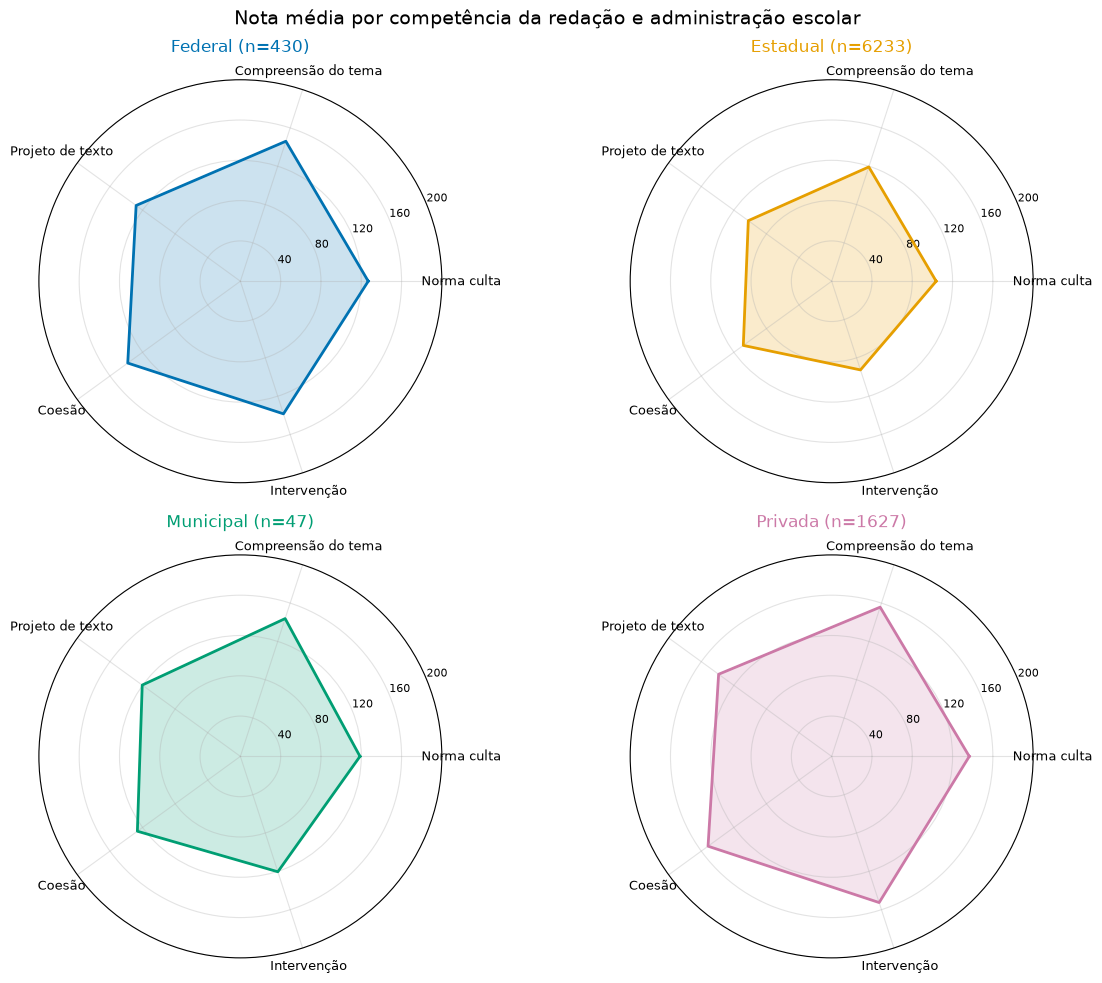

In [21]:
# Médias das competências da redação por dependência administrativa
competencias_redacao = ["NU_NOTA_COMP1", "NU_NOTA_COMP2", "NU_NOTA_COMP3", "NU_NOTA_COMP4", "NU_NOTA_COMP5"]
nomes_competencias = [
    "Norma culta",
    "Compreensão do tema",
    "Projeto de texto",
    "Coesão",
    "Intervenção",
]
tipos_administracao = {1: "Federal", 2: "Estadual", 3: "Municipal", 4: "Privada"}
cores_administracao = {
    "Federal": "#0072B2",
    "Estadual": "#E69F00",
    "Municipal": "#009E73",
    "Privada": "#CC79A7",
}

redacoes_com_competencias = df.dropna(
    subset=competencias_redacao + ["TP_DEPENDENCIA_ADM_ESC"]
).copy()
redacoes_com_competencias["Tipo de escola"] = redacoes_com_competencias[
    "TP_DEPENDENCIA_ADM_ESC"
].map(tipos_administracao)
medias_competencias = redacoes_com_competencias.groupby("Tipo de escola")[competencias_redacao].mean()
quantidades_redacoes = redacoes_com_competencias.groupby("Tipo de escola").size()

print("Médias finais por competência e tipo de administração:")
display(medias_competencias.reindex(tipos_administracao.values()).round(1))

angulos = [posicao / len(nomes_competencias) * 2 * 3.141592653589793 for posicao in range(len(nomes_competencias))]
angulos_fechados = angulos + angulos[:1]
fig, eixos = plt.subplots(2, 2, figsize=(12, 10), subplot_kw={"polar": True})

for ax, tipo in zip(eixos.flat, tipos_administracao.values()):
    if tipo not in medias_competencias.index:
        ax.set_title(f"{tipo} — sem dados")
        ax.set_axis_off()
        continue

    valores = medias_competencias.loc[tipo].tolist()
    valores_fechados = valores + valores[:1]
    cor = cores_administracao[tipo]

    ax.plot(angulos_fechados, valores_fechados, color=cor, linewidth=2)
    ax.fill(angulos_fechados, valores_fechados, color=cor, alpha=0.2)
    ax.set_xticks(angulos)
    ax.set_xticklabels(nomes_competencias, fontsize=9)
    ax.set_ylim(0, 200)
    ax.set_yticks([40, 80, 120, 160, 200])
    ax.set_yticklabels(["40", "80", "120", "160", "200"], fontsize=8)
    ax.set_title(f"{tipo} (n={quantidades_redacoes.get(tipo, 0)})", color=cor, pad=20)
    ax.grid(alpha=0.35)

fig.suptitle("Nota média por competência da redação e administração escolar", fontsize=14)
plt.tight_layout()
plt.savefig("graficos/05_radar_competencias_por_administracao.png", dpi=160, bbox_inches="tight")
plt.show()

Quantidade de redações com nota maior que zero: 20327
Média de cada competência:
NU_NOTA_COMP1    120.6
NU_NOTA_COMP2    136.9
NU_NOTA_COMP3    119.2
NU_NOTA_COMP4    126.7
NU_NOTA_COMP5    114.0
dtype: float64


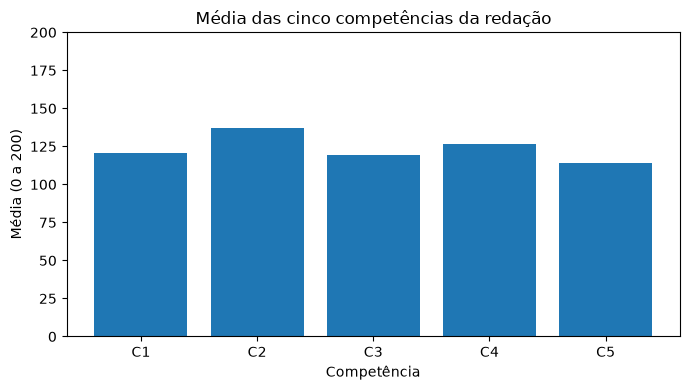

In [22]:
#Média das cinco competências da redação

redacoes_validas = df[df["NU_NOTA_REDACAO"] > 0]
media_competencias = redacoes_validas[competencias].mean().round(1)

print("Quantidade de redações com nota maior que zero:", len(redacoes_validas))
print("Média de cada competência:")
print(media_competencias)

nomes_competencias = ["C1", "C2", "C3", "C4", "C5"]
plt.figure(figsize=(7, 4))
plt.bar(nomes_competencias, media_competencias.values)
plt.title("Média das cinco competências da redação")
plt.xlabel("Competência")
plt.ylabel("Média (0 a 200)")
plt.ylim(0, 200)
plt.tight_layout()
plt.savefig("graficos/04_competencias.png")
plt.show()

                  Participantes com nota de LC  Média em LC
Língua escolhida                                           
Espanhol                                  8744        505.7
Inglês                                   12889        550.2

Escolhas da língua estrangeira:
Língua escolhida
Inglês      16864
Espanhol    13135
Name: count, dtype: int64


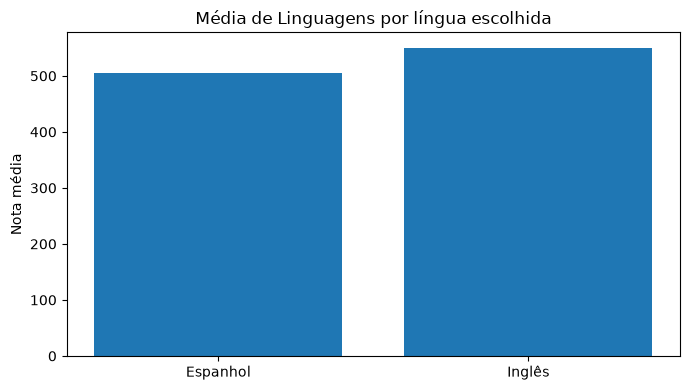

In [24]:
#Língua estrangeira e nota de Linguagens

linguas = {0: "Inglês", 1: "Espanhol"}

linguagens = df.copy()
linguagens["Língua escolhida"] = linguagens["TP_LINGUA"].map(linguas)

escolhas = linguagens["Língua escolhida"].value_counts()
media_lc = linguagens.groupby("Língua escolhida")["NU_NOTA_LC"].mean().round(1)
qtd_lc = linguagens.groupby("Língua escolhida")["NU_NOTA_LC"].count()

print(pd.DataFrame({"Participantes com nota de LC": qtd_lc,
                    "Média em LC": media_lc}))
print("\nEscolhas da língua estrangeira:")
print(escolhas)

plt.figure(figsize=(7, 4))
plt.bar(media_lc.index, media_lc.values)
plt.title("Média de Linguagens por língua escolhida")
plt.ylabel("Nota média")
plt.tight_layout()
plt.savefig("graficos/06_linguas.png")
plt.show()

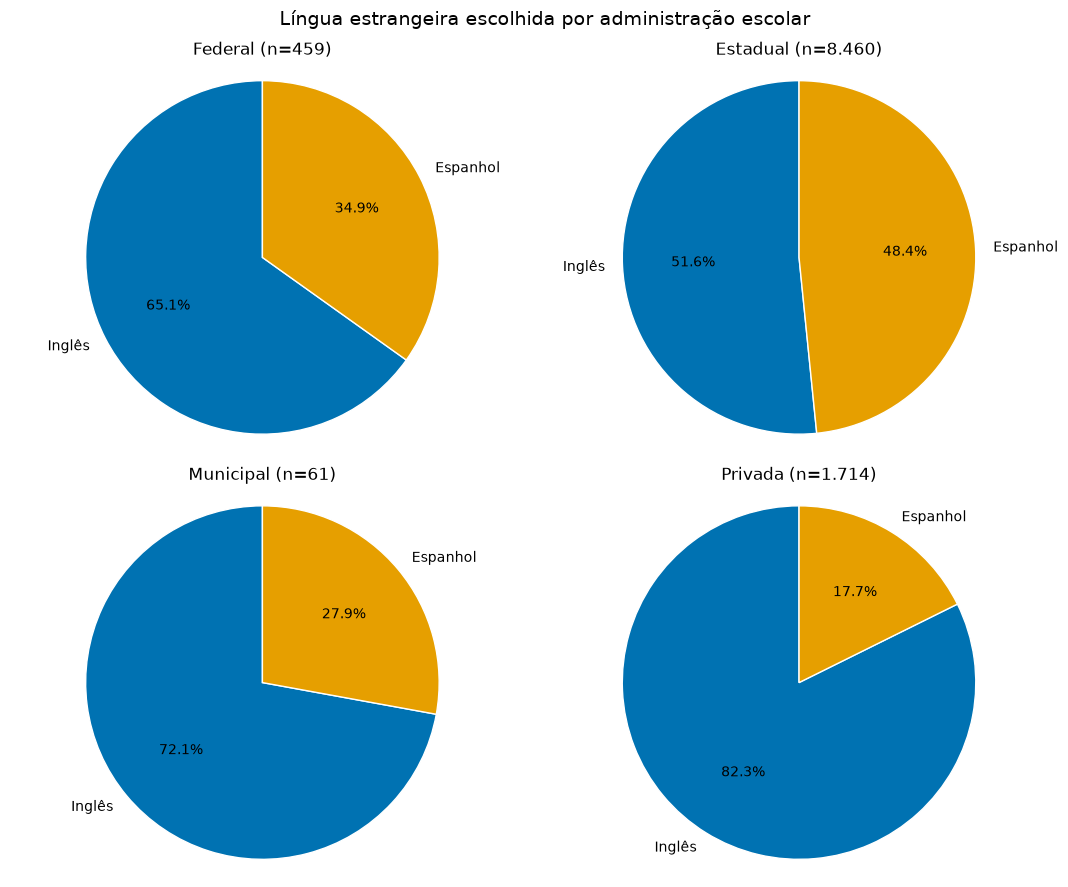

Quantidade de alunos por língua e tipo de administração:


Língua escolhida,Inglês,Espanhol
Tipo de escola,,
Federal,299,160
Estadual,4365,4095
Municipal,44,17
Privada,1411,303


In [25]:
# Língua estrangeira escolhida por tipo de administração escolar
escolas_por_administracao = {1: "Federal", 2: "Estadual", 3: "Municipal", 4: "Privada"}
nomes_linguas = {0: "Inglês", 1: "Espanhol"}
cores_linguas = ["#0072B2", "#E69F00"]

alunos_com_escola_e_lingua = df.dropna(
    subset=["TP_DEPENDENCIA_ADM_ESC", "TP_LINGUA"]
).copy()
alunos_com_escola_e_lingua["Tipo de escola"] = alunos_com_escola_e_lingua[
    "TP_DEPENDENCIA_ADM_ESC"
].map(escolas_por_administracao)
alunos_com_escola_e_lingua["Língua escolhida"] = alunos_com_escola_e_lingua[
    "TP_LINGUA"
].map(nomes_linguas)
alunos_com_escola_e_lingua = alunos_com_escola_e_lingua.dropna(
    subset=["Tipo de escola", "Língua escolhida"]
)

fig, eixos = plt.subplots(2, 2, figsize=(11, 9))
for ax, tipo in zip(eixos.flat, escolas_por_administracao.values()):
    escolhas_tipo = alunos_com_escola_e_lingua.loc[
        alunos_com_escola_e_lingua["Tipo de escola"] == tipo,
        "Língua escolhida"
    ].value_counts().reindex(nomes_linguas.values(), fill_value=0)

    if escolhas_tipo.sum() > 0:
        ax.pie(
            escolhas_tipo.values,
            labels=escolhas_tipo.index,
            autopct="%1.1f%%",
            startangle=90,
            colors=cores_linguas,
            wedgeprops={"edgecolor": "white", "linewidth": 1},
        )
        ax.set_title(f"{tipo} (n={escolhas_tipo.sum():,})".replace(",", "."))
    else:
        ax.set_title(f"{tipo} (sem dados)")
        ax.text(0.5, 0.5, "Sem alunos com idioma informado", ha="center", va="center", transform=ax.transAxes)

    ax.axis("equal")

fig.suptitle("Língua estrangeira escolhida por administração escolar", fontsize=14)
plt.tight_layout()
plt.savefig("graficos/07_lingua_por_administracao.png", dpi=160, bbox_inches="tight")
plt.show()

print("Quantidade de alunos por língua e tipo de administração:")
display(pd.crosstab(
    alunos_com_escola_e_lingua["Tipo de escola"],
    alunos_com_escola_e_lingua["Língua escolhida"]
).reindex(index=escolas_por_administracao.values(), columns=nomes_linguas.values(), fill_value=0))